# Understanding Derivatives

In [17]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [18]:
def f(x):
    return 3*x**2 - 4*x + 5

In [19]:
f(3.0)

20.0

In [20]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
ys

array([100.    ,  91.6875,  83.75  ,  76.1875,  69.    ,  62.1875,
        55.75  ,  49.6875,  44.    ,  38.6875,  33.75  ,  29.1875,
        25.    ,  21.1875,  17.75  ,  14.6875,  12.    ,   9.6875,
         7.75  ,   6.1875,   5.    ,   4.1875,   3.75  ,   3.6875,
         4.    ,   4.6875,   5.75  ,   7.1875,   9.    ,  11.1875,
        13.75  ,  16.6875,  20.    ,  23.6875,  27.75  ,  32.1875,
        37.    ,  42.1875,  47.75  ,  53.6875])

In [21]:
plt.plot(xs, ys)

In [22]:
# try to get a derivative

h = 0.001
x = 3.0
f(x)

20.0

In [23]:
f(x+h)

20.014003000000002

In [24]:
(f(x+h) - f(x)) / h

14.00300000000243

In [25]:
x = 2/3
h = 0.001
(f(x+h) - f(x)) / h

0.0029999999995311555

In [26]:
# add a bit of complexity
a = 2.0
b = -3.0
c = 10.0
d = a*b + c
print(d)

4.0


In [27]:
h = 0.0001

# inputs
a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
a += h
d2 = a*b + c

print("d1:", d1)
print("d2:", d2)
print("slope:", (d2-d1)/h)


d1: 4.0
d2: 3.999699999999999
slope: -3.000000000010772


In [28]:
h = 0.0001

# inputs
a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
b += h
d2 = a*b + c

print("d1:", d1)
print("d2:", d2)
print("slope:", (d2-d1)/h)


d1: 4.0
d2: 4.0002
slope: 2.0000000000042206


In [29]:
h = 0.0001

# inputs
a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
c += h
d2 = a*b + c

print("d1:", d1)
print("d2:", d2)
print("slope:", (d2-d1)/h)


d1: 4.0
d2: 4.0001
slope: 0.9999999999976694


# Neural Networks

In [30]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''): # tuple
        self.data = data
        self.grad = 0.0
        self._prev = set(_children) # make it a set
        self._op = _op
        self.label = label

    def __repr__ (self):
        return f"Value(data={self.data})"
    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        return out
    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        return out
a  = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label='f')
L = d*f; L.label = 'L'

In [31]:
a.__mul__(b).__add__(c)

Value(data=4.0)

In [32]:
print(d)
print(d._prev)
print(d._op)

Value(data=4.0)
{Value(data=-6.0), Value(data=10.0)}
+


In [33]:
!pip install graphviz

In [34]:
from graphviz import Digraph
def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set (), set ()
    def build (v):
        if v not in nodes: 
            nodes.add (v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges
def draw_dot (root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label=n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)
    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot

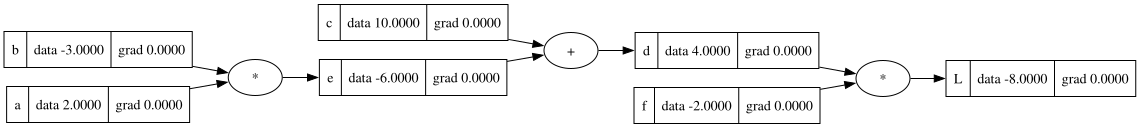

In [35]:
draw_dot(L)

# Backpropagation
start from the back

In [36]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''): # tuple
        self.data = data
        self.grad = 0.0
        self._prev = set(_children) # make it a set
        self._op = _op
        self.label = label

    def __repr__ (self):
        return f"Value(data={self.data})"
    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        return out
    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        return out
a  = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label='f')
L = d*f; L.label = 'L'

In [37]:
# loss의 자기 자신에 대한 gradient는 1.0으로 설정
L.grad = 1.0
f.grad = 4.0 # same as d's value
d.grad = -2.0 # same as f's value


In [39]:
# loss 확인하는 함수. h를 어디에 붙이느냐에 따라 gradient in respect of @@@가 달라진다
def lol():

    h = 0.001

    a  = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label = 'e'
    d = e + c; d.label = 'd'
    f = Value(-2.0, label='f')
    L = d*f; L.label = 'L'
    L1 = L.data

    a  = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label = 'e'
    d = e + c; d.label = 'd'
    f = Value(-2.0, label='f')
    f.data += h # 여기서는 f에 h를 붙여서 gradient in respect of f를 구한다
    L = d*f; L.label = 'L'
    L2 = L.data

    print((L2-L1)/h)

lol()

3.9999999999995595


In [40]:
# 우리는 결국에는 local gradient들이 곱해진 (chain rule) 현태로 최종 loss에 대한 각 intermediate variable들의 gradient를 계산한다.
# 덧셈의 경우 gradient가 1이 되고
# 곱셈의 경우 gradient가 다른 factor의 값이 된다.
# 그러므로 c.grad = -2 (이전 스텝에서의 gradient) * 1 (덧셈의 gradient) = -2
# e 의 경우 동일
c.grad = -2
e.grad = -2

# a의 경우 e의 gradient * b의 값 = -2 * -3 = 6
# b의 경우 e의 gradient * a의 값 = -2 * 2 = -4
a.grad = 6
b.grad = -4

In [41]:
from graphviz import Digraph
def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set (), set ()
    def build (v):
        if v not in nodes: 
            nodes.add (v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges
def draw_dot (root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label=n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)
    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot

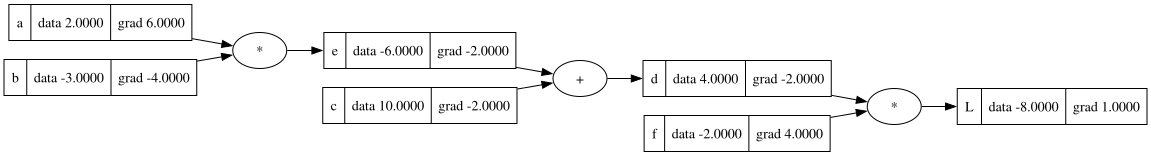

In [42]:
draw_dot(L)

# Forward pass

In [43]:
# adjust the values of leaf nodes (a, b, c, f) in the direction that increases L
# if gradient is positive, we want to increase the value of the variable
# if gradient is negative, we want to decrease the value of the variable
    # thus using the negative gradient to update is helpful.
a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f.data += 0.01 * f.grad

# manual backpropagation of neural networks

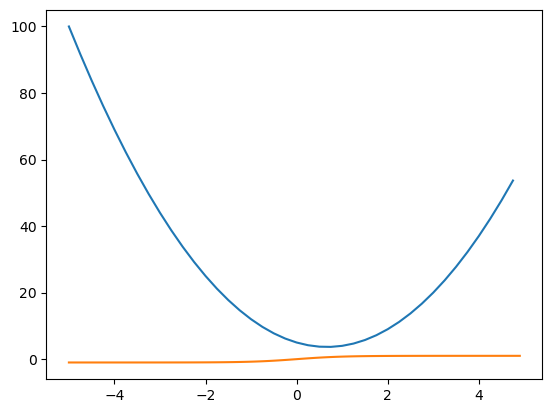

In [44]:
# 조금 더 복잡한 형태의 neural network을 만들어보자
# activation function: 입력값이 매우 크든 혹은 작든, 좁은 영억 (-1, 1) 혹은 (0, 1)로 mapping해주는 함수
# linear transformation을 통해서 나온 값이 activation function을 통과하면, nonlinear한 형태로 mapping이 된다. 이는 neural network의 핵심적인 부분이다.
# 훨씬 복잡한 패턴을 나타낼 수 있게 됨

plt.plot(np.arange(-5, 5, 0.1), np.tanh(np.arange(-5, 5, 0.1)))
plt.show()

In [45]:
# tanh는 덧셈과 곱셈만으로 만들어낼 수 없기에 미리 함수를 만든다
class Value:
    def __init__(self, data, _children=(), _op='', label=''): # tuple
        self.data = data
        self.grad = 0.0
        self._prev = set(_children) # make it a set
        self._op = _op
        self.label = label

    def __repr__ (self):
        return f"Value(data={self.data})"
    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        return out
    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        return out
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)
        out = Value(t, (self,), 'tanh')
        return out
a  = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label='f')
L = d*f; L.label = 'L'

In [46]:
# inputs x1,x2
x1 = Value (2.0, label='x1')
x2 = Value (0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value (1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')

# x1w1 + x2w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

# activation function
o = n.tanh(); o.label = 'o'

In [47]:
# tanh의 derivative는 1 - tanh(x)^2이다. 따라서 chain rule을 적용하면, o의 gradient * (1 - o^2)가 n의 gradient가 된다.
o.grad = 1.0
n.grad = o.grad * (1 - o.data ** 2)
# 근데 일단 여기서는 숫자를 위해 아래와 같이 써줌
n.grad = 0.5

# 계속 backpropagation을 진행하면,
x1w1x2w2.grad = n.grad * 1
b.grad = n.grad * 1

# 다음 layer도 더하기임
x2w2.grad = x1w1x2w2.grad * 1
x1w1.grad = x1w1x2w2.grad * 1

# 다음 layer는 곱하기임
x2.grad = x2w2.grad * w2.data
w2.grad = x2w2.grad * x2.data
x1.grad = x1w1.grad * w1.data
w1.grad = x1w1.grad * x1.data


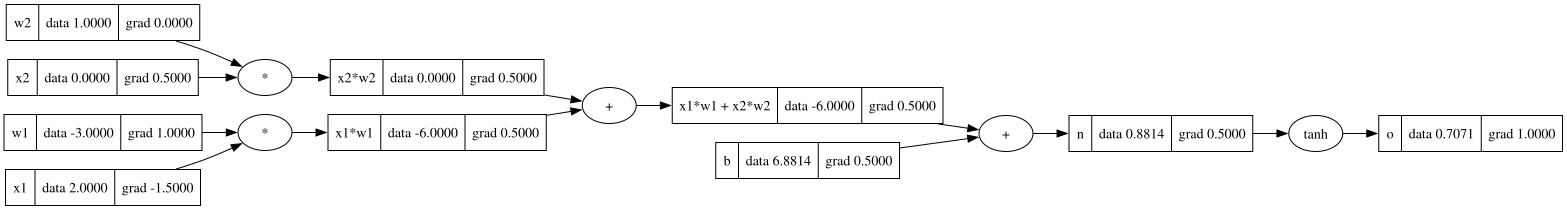

In [48]:
draw_dot(o)

# lets not do this manually..

In [49]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''): # tuple
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None # function that does nothing - but is intended to be overwritten by the chain rule
        self._prev = set(_children) # make it a set
        self._op = _op
        self.label = label

    def __repr__ (self):
        return f"Value(data={self.data})"
    
    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad += 1.0 * out.grad # 여기서 그냥 = 이 아니라 += 인 이유는 하나의 노드가 여러 노드의 input이 될 수 있기 때문이다. 따라서 이전에 계산된 gradient가 있을 수 있으므로, +=로 더해주는 것이 맞다.
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out
    
    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out
    
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)
        out = Value(t, (self,), 'tanh')
        def _backward():
            self.grad += (1 - t ** 2) * out.grad
        out._backward = _backward
        return out



In [50]:
# inputs x1,x2
x1 = Value (2.0, label='x1')
x2 = Value (0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value (1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')


# x1w1 + x2w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

# activation function
o = n.tanh(); o.label = 'o'

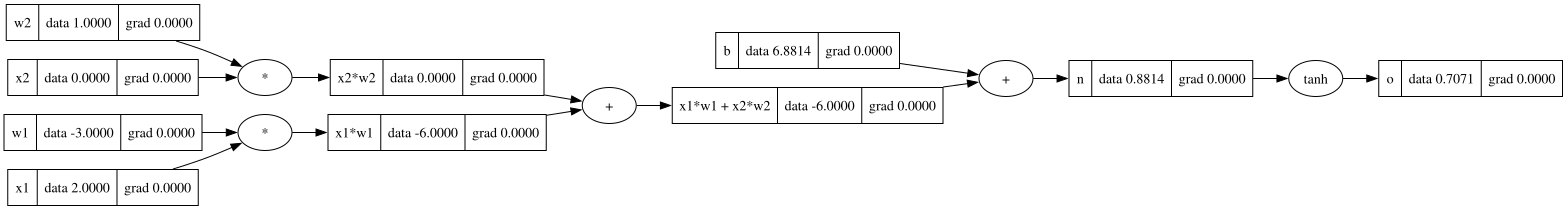

In [51]:
draw_dot(o)

In [52]:
o.grad = 1.0

In [53]:
o._backward() # o와 연결된 바로 직전 layer에 대한 gradient를 계산한다. (n의 gradient)

In [54]:
n._backward()

In [55]:
b._backward() # 이건 아무 일도 일어나지 않음

In [56]:
x1w1x2w2._backward()
x1w1._backward()
x2w2._backward()

In [57]:
# 아직도 이거 manual하게 하고 있다...

# 진짜 automate 하기: topological sort 해서 뒤에서부터 진행하기

In [58]:
topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)
topo

[Value(data=6.881373587019543),
 Value(data=1.0),
 Value(data=0.0),
 Value(data=0.0),
 Value(data=-3.0),
 Value(data=2.0),
 Value(data=-6.0),
 Value(data=-6.0),
 Value(data=0.8813735870195432),
 Value(data=0.7071067811865476)]

In [59]:
o.grad = 1.0

topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)

for node in reversed(topo):
    node._backward()

In [60]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''): # tuple
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None # function that does nothing - but is intended to be overwritten by the chain rule
        self._prev = set(_children) # make it a set
        self._op = _op
        self.label = label

    def __repr__ (self):
        return f"Value(data={self.data})"
    
    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad += 1.0 * out.grad # 여기서 그냥 = 이 아니라 += 인 이유는 하나의 노드가 여러 노드의 input이 될 수 있기 때문이다. 따라서 이전에 계산된 gradient가 있을 수 있으므로, +=로 더해주는 것이 맞다.
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out
    
    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out
    
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)
        out = Value(t, (self,), 'tanh')
        def _backward():
            self.grad += (1 - t ** 2) * out.grad
        out._backward = _backward
        return out

    # called on the output node to initiate the backward pass
    # goes to all children nodes and calls their _backward() methods
    def backward(self):
        # topological order all of the children in the graph
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

In [61]:
# inputs x1,x2
x1 = Value (2.0, label='x1')
x2 = Value (0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value (1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')


# x1w1 + x2w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

# activation function
o = n.tanh(); o.label = 'o'

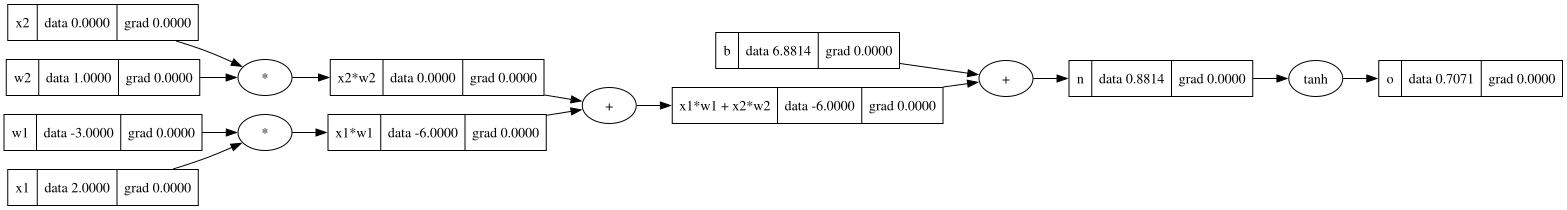

In [62]:
draw_dot(o)

In [63]:
o.backward()

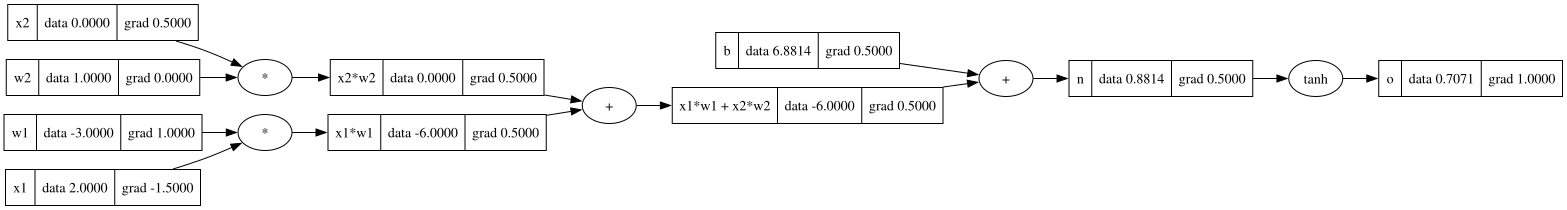

In [64]:
draw_dot(o)

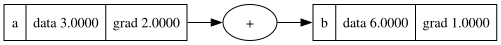

In [65]:
a = Value(3.0, label='a')
b = a + a; b.label = 'b'
b.backward()
draw_dot(b)

# lets add more features: addition, multiplication with numerical values (that are not Value instances), exponents, etc.

In [111]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''): # tuple
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None # function that does nothing - but is intended to be overwritten by the chain rule
        self._prev = set(_children) # make it a set
        self._op = _op
        self.label = label

    def __repr__ (self):
        return f"Value(data={self.data})"
    
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other) # 숫자와의 연산도 가능하게끔
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad += 1.0 * out.grad # 여기서 그냥 = 이 아니라 += 인 이유는 하나의 노드가 여러 노드의 input이 될 수 있기 때문이다. 따라서 이전에 계산된 gradient가 있을 수 있으므로, +=로 더해주는 것이 맞다.
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out
    
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other) # 숫자와의 연산도 가능하게끔
        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out
    
    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data ** other, (self,), f'**{other}')
        def _backward():
            self.grad += (other * self.data ** (other - 1)) * out.grad
        out._backward = _backward
        return out
    
    def __rsub__(self,other):
        return other + (-self)
    
    def __rmul__(self, other): # 반대로 숫자 * Value의 경우를 위해서, __mul__이 아닌 rmul을 정의해준다. (즉, 숫자가 왼쪽에 있을 때)
        return self * other

    def __truediv__(self, other):
        return self * other**-1
    
    def __neg__(self): # unary negation
        return self * -1
    
    def __sub__(self, other):
        return self + (-other)

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)
        out = Value(t, (self,), 'tanh')
        def _backward():
            self.grad += (1 - t ** 2) * out.grad
        out._backward = _backward
        return out
    
    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), 'exp')
        def _backward():
            self.grad += out.data * out.grad # derivative of exp(x) is exp(x), which is out.data
        out._backward = _backward
        return out

    # called on the output node to initiate the backward pass
    # goes to all children nodes and calls their _backward() methods
    def backward(self):
        # topological order all of the children in the graph
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

In [67]:
a = Value(2.0)
b = Value(4.0)
a / b

Value(data=0.5)

In [68]:
# inputs x1,x2
x1 = Value (2.0, label='x1')
x2 = Value (0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value (1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')


# x1w1 + x2w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

# activation function
o = n.tanh(); o.label = 'o'
o.backward()

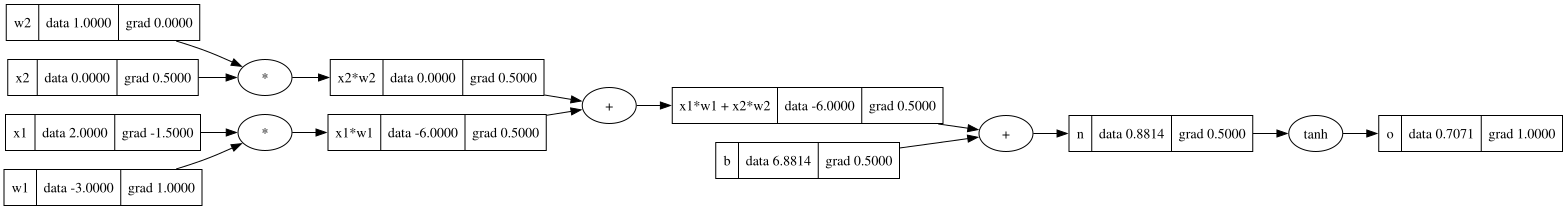

In [69]:
draw_dot(o)

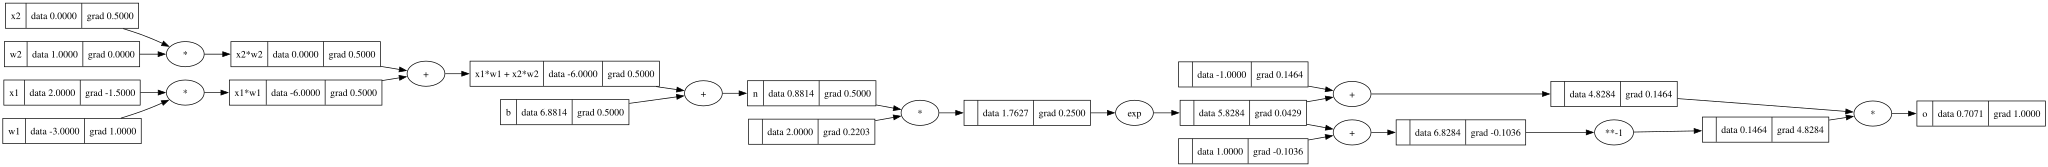

In [70]:
# change tanh into expressions using the methods we implemented in the Value class

# inputs x1,x2
x1 = Value (2.0, label='x1')
x2 = Value (0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value (1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')


# x1w1 + x2w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

# # activation function
# o = n.tanh(); o.label = 'o'
e = (2*n).exp()
o = (e-1) / (e+1)
o.label = 'o'
o.backward()
draw_dot(o)

# Implementing the same thing using PyTorch

In [71]:
!pip install torch

In [72]:
import torch

# tensors: n dimensinal array of scalar values

x1 = torch.Tensor([2.0]).double(); x1.requires_grad = True
x2 = torch.Tensor([0.0]).double(); x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double(); w1.requires_grad = True
w2 = torch.Tensor([1.0]).double(); w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double(); b.requires_grad = True

n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())

0.7071066904050358


In [73]:
torch.Tensor([[1,2,3], [4,5,6]]).shape

torch.Size([2, 3])

In [74]:
torch.Tensor([[1,2,3], [4,5,6]]).dtype

torch.float32

In [75]:
torch.Tensor([[1,2,3], [4,5,6]]).data.item()

RuntimeError: a Tensor with 6 elements cannot be converted to Scalar

In [ ]:
torch.Tensor([[2.0]]).data.item()


2.0

In [ ]:
o.backward()

print('---')
print('x2',  x2.grad.item())
print('w2',  w2.grad.item())
print('x1',  x1.grad.item())
print('w1',  w1.grad.item())

---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


## Neural Network using Pytorch

In [122]:
import random

class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)] # weights
        self.b = Value(random.uniform(-1, 1)) # biases
    
    def __call__(self, x): # given input x, calculate layer's output
        # w * x + b
        # w1*x1 + w2*x2 + ... + b
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out
    
    def parameters(self):
        return self.w + [self.b]
    
class Layer:

    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for N in range(nout)] # in every layer, have nout neurons with inputs nin
    
    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs # if output is a single scalar output the DATA, else output the LIST

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]
        params = []
        for neuron in self.neurons:
            ps = neuron.parameters()
            params.extend(ps)
        return params
class MLP:
    def __init__(self, nin, nouts): # nouts need be be a list of layer sizes
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x) # apply layer after layer
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]


In [123]:
x = [2.0, 3.0, -1.0]
n = MLP(3, [4,4,1]) # 3 inputs, and 3 layers each of size 4, 4, and 1.
n(x)

Value(data=-0.06598300018367564)

# lets make the loss function

In [140]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]

ys = [1.0, -1.0, -1.0, 1.0]

ypred = [n(x) for x in xs] # desired targets
ypred # this is just random and not close to real y

[Value(data=0.020619306674665026),
 Value(data=-0.3168904513802995),
 Value(data=-0.09570676536404724),
 Value(data=-0.19694508480868794)]

In [141]:
[(yout - ygt)**2 for ygt, yout in zip(ys, ypred)]

[Value(data=0.9591865424584138),
 Value(data=0.466638655415411),
 Value(data=0.8177462542083543),
 Value(data=1.4326775360476773)]

In [142]:
loss = sum(((yout - ygt)**2 for ygt, yout in zip(ys, ypred)), Value(0.0))
loss

Value(data=3.6762489881298563)

In [143]:
loss.backward()

In [144]:
n.layers[0].neurons[0].w[0].data, n.layers[0].neurons[0].w[0].grad

(0.9294384440616499, 0.1515127963324695)

In [145]:
list(zip(ys, ypred))

[(1.0, Value(data=0.020619306674665026)),
 (-1.0, Value(data=-0.3168904513802995)),
 (-1.0, Value(data=-0.09570676536404724)),
 (1.0, Value(data=-0.19694508480868794))]

In [146]:
n.parameters()

[Value(data=0.9294384440616499),
 Value(data=-0.9783067663977206),
 Value(data=0.9563078120014632),
 Value(data=0.24022515000162625),
 Value(data=-0.5088850757834603),
 Value(data=-0.5094858238440344),
 Value(data=-0.3426454221234965),
 Value(data=0.5499643101851561),
 Value(data=-0.4372186332001933),
 Value(data=-0.9405167870083919),
 Value(data=-0.5696084071633817),
 Value(data=0.6454849867186415),
 Value(data=-0.07211342042037308),
 Value(data=0.33844866543979274),
 Value(data=-0.2577717737367173),
 Value(data=-0.1499586515373527),
 Value(data=0.32220872287488717),
 Value(data=-0.7207372175197512),
 Value(data=0.11112961566416718),
 Value(data=-0.6490500792869112),
 Value(data=-0.7940391947317211),
 Value(data=0.11823938529565343),
 Value(data=0.5928778852083406),
 Value(data=0.947957206621017),
 Value(data=0.025838008905854602),
 Value(data=0.8286291766296034),
 Value(data=-0.47034906617709415),
 Value(data=-0.0842555759848148),
 Value(data=-0.7553711118450942),
 Value(data=0.11538

In [147]:
# gradiet is pointing to the direction of increasing loss
# since we need to decrease loss
for p in n.parameters():
    p.data += -0.01 * p.grad

In [148]:
n.layers[0].neurons[0].w[0].data, n.layers[0].neurons[0].w[0].grad

(0.9279233160983252, 0.1515127963324695)

In [ ]:
ypred = [n(x) for x in xs]
loss = sum(((yout - ygt)**2 for ygt, yout in zip(ys, ypred)), Value(0.0))
loss # loss decreased!

Value(data=3.123251313888165)

In [156]:
# forward pass - backward pass - update

n = MLP(3, [4,4,1])

xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]

ys = [1.0, -1.0, -1.0, 1.0]

for k in range(20):
    # forward pass
    ypred = [n(x) for x in xs]
    loss = sum(((yout - ygt)**2 for ygt, yout in zip(ys, ypred)), Value(0.0))

    # backward pass -- dont forget to flush all the grads to zero!
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()

    # update
    for p in n.parameters():
        p.data += -0.05 * p.grad

    print(k, loss.data)


0 7.375139642791196
1 6.6828305869019164
2 4.563421737050135
3 2.2556914455193215
4 1.3577805824611315
5 0.7774025393740721
6 0.47483451895866613
7 0.3219187754131935
8 0.23902771077994459
9 0.18714740871020813
10 0.15227212386325248
11 0.1275251877331795
12 0.10920257136813866
13 0.09516902174747241
14 0.08412145145726722
15 0.07522583749013621
16 0.06792660226115436
17 0.06184091238998851
18 0.056697227607065616
19 0.052298083348842526


In [157]:
ypred

[Value(data=0.877771521797847),
 Value(data=-0.8576673940241597),
 Value(data=-0.880126485717768),
 Value(data=0.9477500974643775)]